In [2]:
# imports

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

DIRETORIO = Path("/content/dataset")
NUM_SUJEITOS = 4  # ampliar para 35 quando todos os arquivos estiverem disponíveis
FREQUENCIA_AMOSTRAGEM = 250  # Hz, conforme a documentação do dataset
SHAPE_POR_SUJEITO = (64, 1500, 40, 6)


ModuleNotFoundError: No module named 'numpy'

In [ ]:
dados_sujeitos = []

for i in range(1, NUM_SUJEITOS + 1):
    caminho = DIRETORIO / f"S{i}.mat"
    arquivo_mat = loadmat(caminho)
    dados_sujeito = arquivo_mat["data"]
    dados_sujeitos.append(dados_sujeito)

# Formato final: (sujeitos, canais, tempo, alvos, blocos)
data = np.stack(dados_sujeitos, axis=0)
print("Shape unificado:", data.shape)
print("Tipo dos dados:", data.dtype)
print("Valores NaN:", np.isnan(data).sum())
print("Valores infinitos:", np.isinf(data).sum())

assert data.shape == (NUM_SUJEITOS, *SHAPE_POR_SUJEITO)


Shape unificado: (4, 64, 1500, 40, 6)
Tipo dos dados: float64
Valores NaN: 0
Valores infinitos: 0


In [ ]:
caminho_freq_phase = DIRETORIO / "Freq_Phase.mat"
if not caminho_freq_phase.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {caminho_freq_phase}")

freq_phase = loadmat(caminho_freq_phase)

if "freqs" not in freq_phase or "phases" not in freq_phase:
    raise KeyError("O arquivo deve conter as variáveis 'freqs' e 'phases'.")

freqs = np.asarray(freq_phase["freqs"]).ravel()
phases = np.asarray(freq_phase["phases"]).ravel()

assert len(freqs) == 40, f"Esperadas 40 frequências, encontradas {len(freqs)}"
assert len(phases) == 40, f"Esperadas 40 fases, encontradas {len(phases)}"

print("Índice | Frequência (Hz) | Fase (rad)")
for alvo, (freq, phase) in enumerate(zip(freqs, phases)):
    print(f"{alvo:>6} | {freq:>14.1f} | {phase:>10.4f}")


Índice | Frequência (Hz) | Fase (rad)
     0 |            8.0 |     0.0000
     1 |            9.0 |     1.5708
     2 |           10.0 |     3.1416
     3 |           11.0 |     4.7124
     4 |           12.0 |     0.0000
     5 |           13.0 |     1.5708
     6 |           14.0 |     3.1416
     7 |           15.0 |     4.7124
     8 |            8.2 |     1.5708
     9 |            9.2 |     3.1416
    10 |           10.2 |     4.7124
    11 |           11.2 |     0.0000
    12 |           12.2 |     1.5708
    13 |           13.2 |     3.1416
    14 |           14.2 |     4.7124
    15 |           15.2 |     0.0000
    16 |            8.4 |     3.1416
    17 |            9.4 |     4.7124
    18 |           10.4 |     0.0000
    19 |           11.4 |     1.5708
    20 |           12.4 |     3.1416
    21 |           13.4 |     4.7124
    22 |           14.4 |     0.0000
    23 |           15.4 |     1.5708
    24 |            8.6 |     4.7124
    25 |            9.6 |     0.0000


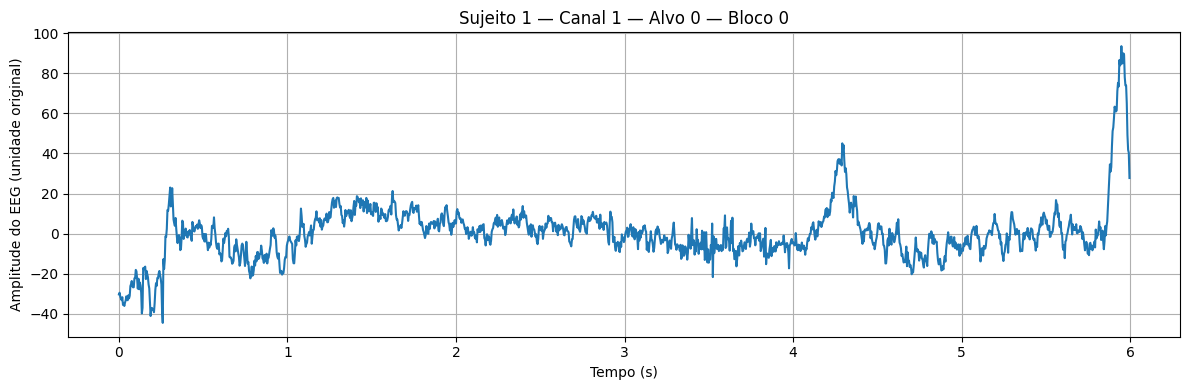

In [ ]:
# Índices Python: sujeito 0, canal 0, alvo 0, bloco 0
sinal = data[0, 0, :, 0, 0]
tempo = np.arange(sinal.size) / FREQUENCIA_AMOSTRAGEM

plt.figure(figsize=(12, 4))
plt.plot(tempo, sinal)
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude do EEG (unidade original)")
plt.title("Sujeito 1 — Canal 1 — Alvo 0 — Bloco 0")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
# Original: (sujeitos, canais, tempo, alvos, blocos)
# Novo:     (sujeitos, tentativas, canais, tempo)
# A ordem das tentativas é: alvo 0/blocos 0–5, alvo 1/blocos 0–5, ...
X = data.transpose(0, 3, 4, 1, 2).reshape(
    NUM_SUJEITOS, 40 * 6, 64, 1500
)

# Rótulos alinhados à ordem das tentativas acima
y = np.repeat(np.arange(40), 6)
y_freq = np.repeat(freqs, 6)
y_phase = np.repeat(phases, 6)
blocos = np.tile(np.arange(6), 40)

print("X (sujeitos, tentativas, canais, tempo):", X.shape)
print("y (índice do alvo):", y.shape)
print("y_freq (Hz):", y_freq.shape)
print("y_phase (rad):", y_phase.shape)
print("blocos:", blocos.shape)


X (sujeitos, tentativas, canais, tempo): (4, 240, 64, 1500)
y (índice do alvo): (240,)
y_freq (Hz): (240,)
y_phase (rad): (240,)
blocos: (240,)


In [ ]:
# Conferir exemplos de tentativas do primeiro sujeito.
sujeito = 0
indices_teste = [0, 1, 5, 6, 7, 239]

for i in indices_teste:
    alvo = y[i]
    bloco = blocos[i]

    # Comparar com a posição correspondente no array original
    sinal_original = data[sujeito, :, :, alvo, bloco]
    sinal_organizado = X[sujeito, i]
    assert np.array_equal(sinal_original, sinal_organizado)

    # Confirmar também frequência e fase do alvo
    assert y_freq[i] == freqs[alvo]
    assert y_phase[i] == phases[alvo]

    print(
        f"Tentativa {i:3}: alvo={alvo:2}, bloco={bloco}, "
        f"frequência={y_freq[i]:.1f} Hz, fase={y_phase[i]:.4f} rad"
    )

print("\nVerificações de alinhamento concluídas.")


Tentativa   0: alvo= 0, bloco=0, frequência=8.0 Hz, fase=0.0000 rad
Tentativa   1: alvo= 0, bloco=1, frequência=8.0 Hz, fase=0.0000 rad
Tentativa   5: alvo= 0, bloco=5, frequência=8.0 Hz, fase=0.0000 rad
Tentativa   6: alvo= 1, bloco=0, frequência=9.0 Hz, fase=1.5708 rad
Tentativa   7: alvo= 1, bloco=1, frequência=9.0 Hz, fase=1.5708 rad
Tentativa 239: alvo=39, bloco=5, frequência=15.8 Hz, fase=4.7124 rad

Verificações de alinhamento concluídas.
